In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [2]:
iris = load_iris()

X = iris.data
y = iris.target

print("Dataset shape:", X.shape)
print("Number of features:", X.shape[1])

Dataset shape: (150, 4)
Number of features: 4


In [3]:
df = pd.DataFrame(
    X,
    columns=iris.feature_names
)

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [4]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Standardized data:")
print(X_scaled[:5])

Standardized data:
[[-0.90068117  1.01900435 -1.34022653 -1.3154443 ]
 [-1.14301691 -0.13197948 -1.34022653 -1.3154443 ]
 [-1.38535265  0.32841405 -1.39706395 -1.3154443 ]
 [-1.50652052  0.09821729 -1.2833891  -1.3154443 ]
 [-1.02184904  1.24920112 -1.34022653 -1.3154443 ]]


In [5]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("Original number of features:", X.shape[1])
print("Reduced number of features:", X_pca.shape[1])

Original number of features: 4
Reduced number of features: 2


In [6]:
print("Explained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("\nTotal Variance Retained:")
print(sum(pca.explained_variance_ratio_))

Explained Variance Ratio:
[0.72962445 0.22850762]

Total Variance Retained:
0.9581320720000166


In [7]:
pca_df = pd.DataFrame(
    X_pca,
    columns=['Principal_Component_1', 'Principal_Component_2']
)

pca_df['Target'] = y

pca_df.head()

,Principal_Component_1,Principal_Component_2,Target
0,-2.264703,0.480027,0
1,-2.080961,-0.674134,0
2,-2.364229,-0.341908,0
3,-2.299384,-0.597395,0
4,-2.389842,0.646835,0


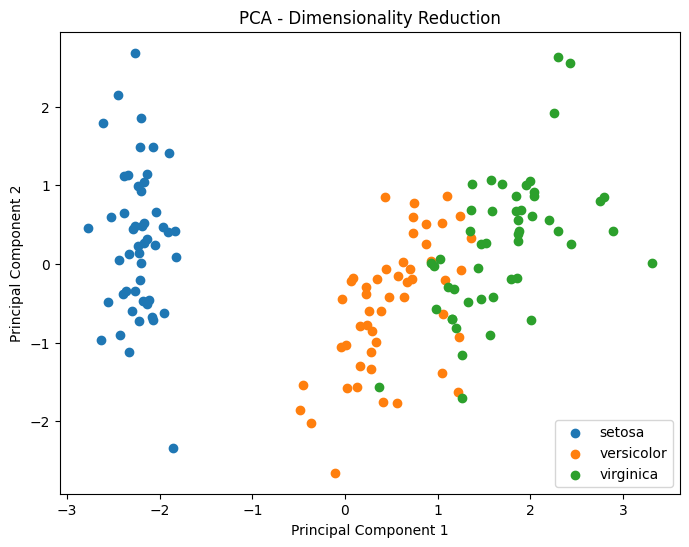

In [8]:
plt.figure(figsize=(8, 6))

for target in range(3):
    plt.scatter(
        X_pca[y == target, 0],
        X_pca[y == target, 1],
        label=iris.target_names[target]
    )

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA - Dimensionality Reduction')
plt.legend()

plt.show()

In [9]:
print("PCA Components:")
print(pca.components_)

PCA Components:
[[ 0.52106591 -0.26934744  0.5804131   0.56485654]
 [ 0.37741762  0.92329566  0.02449161  0.06694199]]
